# Week 9 · Option Greeks & Risk Sensitivities

**How can a call lose value when its stock goes up? What changes when we hedge its delta?**

We start from the European call priced in Week 8 and keep the same spot, strike, maturity, rate, and volatility. The first five sections are the live exercise. The rest of the notebook is Lab 9. Run the code cells in order with a Python 3 kernel and NumPy, pandas, and Matplotlib installed.

[Week 8 notebook](https://github.com/novaquantclub/quant-roadmap/blob/main/Week%208/Week_8_Options_Final_Executed.ipynb) · [Quant Roadmap](https://github.com/novaquantclub/quant-roadmap)

## 1. Start with last week's price

$S$ is spot, $K$ is strike, $T$ is years remaining, $r$ is the annual continuously compounded risk-free rate, $\sigma$ is annual volatility, and $q$ is the continuous dividend yield. Rates, yields, and volatilities enter the code as decimals. The baseline has $q=0$. Prices are in dollars per share.

The pricer and analytical Greeks below are provided. We will use the pricer as a function that we can bump and run again.

In [1]:
from math import erfc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
base = dict(S=100.0, K=95.0, T=0.25, r=0.10, sigma=0.50, q=0.0, kind="call")
MULTIPLIER = 100
DAYS_PER_YEAR = 365

normal_cdf = np.vectorize(lambda x: 0.5 * erfc(-x / np.sqrt(2)), otypes=[float])


def bs_terms(S, K, T, r, sigma, q):
    root_T = np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + sigma**2 / 2) * T) / (sigma * root_T)
    d2 = d1 - sigma * root_T
    spot_discount = np.exp(-q * T)
    discounted_strike = K * np.exp(-r * T)
    return root_T, d1, d2, spot_discount, discounted_strike


def price(S, K, T, r, sigma, q=0.0, kind="call"):
    root_T, d1, d2, spot_discount, discounted_strike = bs_terms(S, K, T, r, sigma, q)
    if kind == "call":
        return S * spot_discount * normal_cdf(d1) - discounted_strike * normal_cdf(d2)
    if kind == "put":
        return discounted_strike * normal_cdf(-d2) - S * spot_discount * normal_cdf(-d1)
    raise ValueError("kind must be 'call' or 'put'")


def greeks(S, K, T, r, sigma, q=0.0, kind="call"):
    root_T, d1, d2, spot_discount, discounted_strike = bs_terms(S, K, T, r, sigma, q)
    density = np.exp(-d1**2 / 2) / np.sqrt(2 * np.pi)
    gamma = spot_discount * density / (S * sigma * root_T)
    vega = S * spot_discount * density * root_T / 100
    diffusion_decay = -S * spot_discount * density * sigma / (2 * root_T)
    if kind == "call":
        delta = spot_discount * normal_cdf(d1)
        annual_theta = diffusion_decay + q * S * delta - r * discounted_strike * normal_cdf(d2)
        rho = T * discounted_strike * normal_cdf(d2) / 100
    elif kind == "put":
        delta = -spot_discount * normal_cdf(-d1)
        annual_theta = diffusion_decay + q * S * delta + r * discounted_strike * normal_cdf(-d2)
        rho = -T * discounted_strike * normal_cdf(-d2) / 100
    else:
        raise ValueError("kind must be 'call' or 'put'")
    return dict(Delta=delta, Gamma=gamma, Vega=vega, Theta=annual_theta / DAYS_PER_YEAR, Rho=rho)


initial_price = price(**base)
initial_greeks = greeks(**base)
print(f"Week 8 Black–Scholes call: ${initial_price:.4f} per share")

Week 8 Black–Scholes call: $13.6953 per share


## 2. Read the Greeks and check them by bumping inputs

| Greek | Derivative convention | Reporting unit |
|---|---|---|
| Delta | $\partial V/\partial S$ | Option dollars per \$1 spot move, or shares per option share |
| Gamma | $\partial^2 V/\partial S^2$ | Change in delta per \$1 spot move |
| Vega | $\partial V/\partial \sigma$ | Option dollars per +1 percentage point of implied volatility |
| Theta | $-\partial V/\partial T$ | Option dollars per calendar day passing |
| Rho | $\partial V/\partial r$ | Option dollars per +1 percentage point of annual rate |

In the derivative column, $T$ is time **remaining**. One day passing reduces $T$ by $1/365$. To report vega and rho per point, divide the decimal-input derivative by 100.

Holding everything except spot fixed. Estimate delta as $(V(100.10)-V(99.90))/0.20$. Gamma uses the center price as well, via $(V(S+h)-2V(S)+V(S-h))/h^2$.

In [2]:
def finite_difference_greeks(inputs):
    spot_bump = 0.10
    rate_bump = 0.0001
    vol_bump = 0.0001
    time_bump = 0.0001  # Years

    def bumped(input_name, amount):
        settings = inputs | {input_name: inputs[input_name] + amount}
        return price(**settings)

    spot_up = bumped("S", spot_bump)
    spot_down = bumped("S", -spot_bump)
    center = price(**inputs)
    delta = (spot_up - spot_down) / (2 * spot_bump)
    gamma = (spot_up - 2 * center + spot_down) / spot_bump**2
    vega = (bumped("sigma", vol_bump) - bumped("sigma", -vol_bump)) / (2 * vol_bump) / 100
    theta = (bumped("T", -time_bump) - bumped("T", time_bump)) / (2 * time_bump) / DAYS_PER_YEAR
    rho = (bumped("r", rate_bump) - bumped("r", -rate_bump)) / (2 * rate_bump) / 100
    return dict(Delta=delta, Gamma=gamma, Vega=vega, Theta=theta, Rho=rho)


comparison = pd.DataFrame({
    "Analytical": initial_greeks,
    "Finite difference": finite_difference_greeks(base),
})
comparison["Absolute difference"] = (comparison["Analytical"] - comparison["Finite difference"]).abs()
display(comparison.round(8))

,Analytical,Finite difference,Absolute difference
Delta,0.666465,0.666465,6.600000e-07
Gamma,0.014547,0.014547,1.000000e-08
Vega,0.181843,0.181843,0.000000e+00
Theta,-0.064327,-0.064327,0.000000e+00
Rho,0.132378,0.132378,0.000000e+00


## 3. See delta and gamma across spot and maturity

The top row is the live discussion. The price and its tangent share a slope at spot 100. The following two panels show how that slope changes across spot and why gamma is concentrated near the strike for a short-dated option. The bottom row shows the other three Greeks in their reporting units. The vertical guide marks the \$95 strike. Both maturities use the same rate, volatility and dividend assumptions.

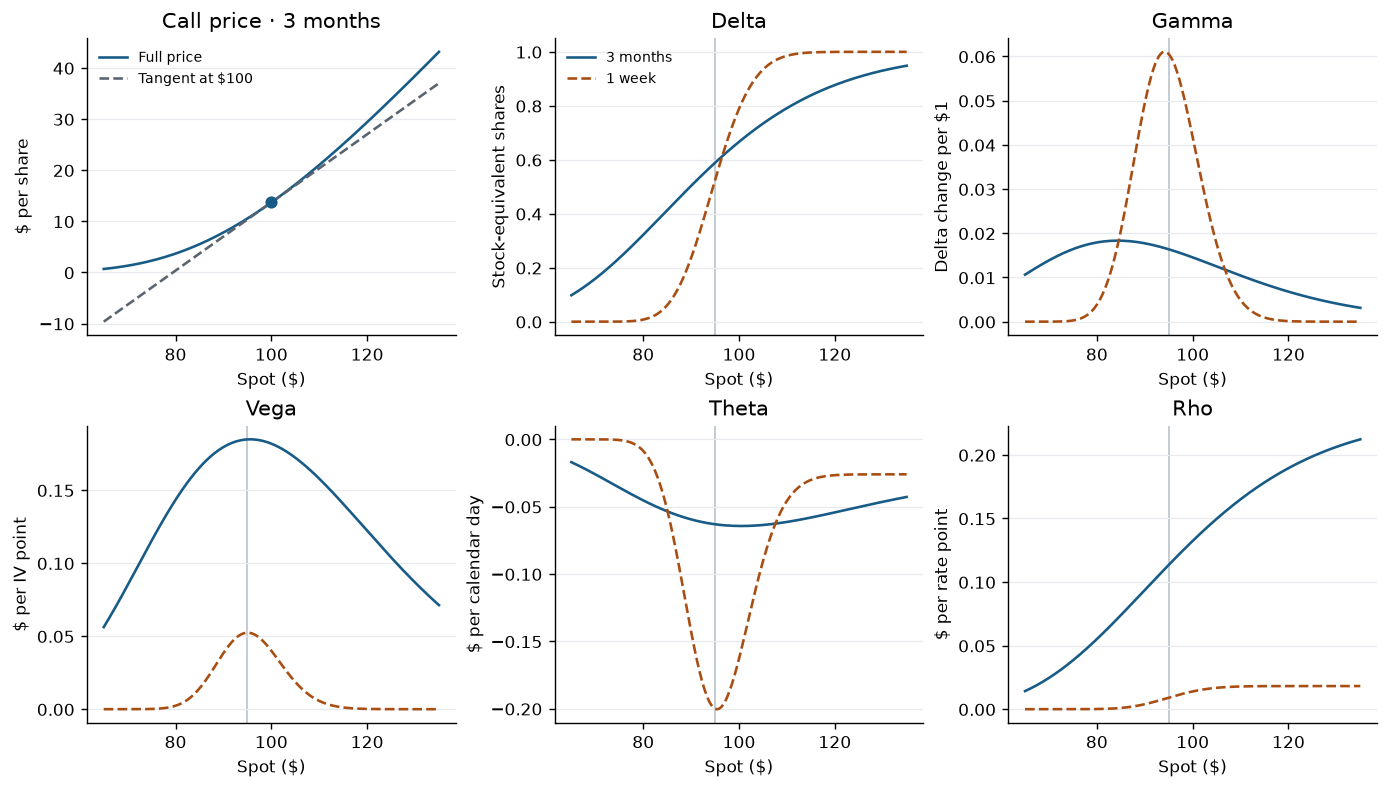

In [3]:
spots = np.linspace(65, 135, 281)
three_months = base | {"S": spots}
one_week = three_months | {"T": 7 / DAYS_PER_YEAR}
curves = [greeks(**three_months), greeks(**one_week)]
blue, orange = "#175b86", "#a94e13"

fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), layout="constrained")
price_ax = axes.flat[0]
price_ax.plot(spots, price(**three_months), color=blue, label="Full price")
tangent = initial_price + initial_greeks["Delta"] * (spots - base["S"])
price_ax.plot(spots, tangent, color="#5a6471", linestyle="--", label="Tangent at $100")
price_ax.scatter(base["S"], initial_price, color=blue, zorder=4)
price_ax.set(xlabel="Spot ($)", ylabel="$ per share", title="Call price · 3 months")
price_ax.legend(frameon=False, fontsize=8)

labels = {
    "Delta": "Stock-equivalent shares",
    "Gamma": "Delta change per $1",
    "Vega": "$ per IV point",
    "Theta": "$ per calendar day",
    "Rho": "$ per rate point",
}
for ax, (name, units) in zip(list(axes.flat)[1:], labels.items()):
    ax.plot(spots, curves[0][name], color=blue, label="3 months")
    ax.plot(spots, curves[1][name], color=orange, linestyle="--", label="1 week")
    ax.axvline(base["K"], color="#bcc5ce", linewidth=1, zorder=0)
    ax.set(xlabel="Spot ($)", ylabel=units, title=name)
axes.flat[1].legend(frameon=False, fontsize=8)
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e7ebef", linewidth=0.7)
display(fig)
plt.close(fig)

## 4. Approximate a spot move

Ask someone to choose a spot move. Before running, compare the sign and likely accuracy of the estimates for a \$1 move and a \$15 move.

$$\Delta V \approx \Delta\,\Delta S + \tfrac12\Gamma(\Delta S)^2$$

The gamma term adds value for a long call for either direction of a spot-only move. A larger move takes us farther from the point where the Greeks were measured.

In [4]:
spot_move = 1.0  # Try 15.0 or -15.0 next.
delta_only = initial_greeks["Delta"] * spot_move
delta_gamma = delta_only + 0.5 * initial_greeks["Gamma"] * spot_move**2
spot_repriced = price(**(base | {"S": base["S"] + spot_move})) - initial_price
print(f"Delta only: {delta_only:+.4f}")
print(f"Delta plus gamma: {delta_gamma:+.4f}")
print(f"Full repricing: {spot_repriced:+.4f}")

Delta only: +0.6665
Delta plus gamma: +0.6737
Full repricing: +0.6737


## 5. Explain tomorrow's P&L and size the hedge

**Scenario.** Spot rises from \$100 to \$101. IV drops from 50% to 45%. One calendar day passes. Rates and dividends stay fixed. Which factor dominates?

Use today's Greeks. Express IV and rate shocks in percentage points and elapsed time in days.

$$
\Delta V \approx \Delta\,\Delta S
+ \tfrac12\Gamma(\Delta S)^2
+ \mathrm{Vega}\,\Delta \mathrm{IV}_{\mathrm{pp}}
+ \Theta\,\mathrm{days}
+ \rho\,\Delta r_{\mathrm{pp}}.
$$

The stock hedge is short $\Delta$ shares per option share for a long call. It cancels the initial linear spot term. Include its stock P&L and compare the combined book with the unhedged call. This one-day example reports option and stock marks before financing and trading costs.

In [5]:
spot_move, iv_points, elapsed_days, rate_points = 1.0, -5.0, 1, 0.0
tomorrow = base | {
    "S": base["S"] + spot_move,
    "sigma": base["sigma"] + iv_points / 100,
    "T": base["T"] - elapsed_days / DAYS_PER_YEAR,
    "r": base["r"] + rate_points / 100,
}
attribution = pd.Series({
    "Delta": initial_greeks["Delta"] * spot_move,
    "Gamma": 0.5 * initial_greeks["Gamma"] * spot_move**2,
    "Vega": initial_greeks["Vega"] * iv_points,
    "Theta": initial_greeks["Theta"] * elapsed_days,
    "Rho": initial_greeks["Rho"] * rate_points,
}, name="P&L ($ per option share)")

estimated = attribution.sum()
repriced = price(**tomorrow) - initial_price
stock_pnl = -initial_greeks["Delta"] * spot_move
display(attribution.round(4).to_frame())
print(f"Greek estimate: {estimated:+.4f}")
print(f"Full repricing: {repriced:+.4f}")
print(f"Residual (repricing minus estimate): {repriced - estimated:+.4f}")
print(f"Initial stock hedge P&L: {stock_pnl:+.4f}")
print(f"Combined option and stock P&L: {repriced + stock_pnl:+.4f}")

new_delta = greeks(**tomorrow)["Delta"]
initial_hedge = -MULTIPLIER * initial_greeks["Delta"]
new_hedge = -MULTIPLIER * new_delta
print(f"Stock position per contract: {initial_hedge:+.2f} → {new_hedge:+.2f} shares")
print(f"Rebalance trade: {new_hedge - initial_hedge:+.2f} shares (negative means sell)")

,P&L ($ per option share)
Delta,0.6665
Gamma,0.0073
Vega,-0.9092
Theta,-0.0643
Rho,0.0000


Greek estimate: -0.2998
Full repricing: -0.2825
Residual (repricing minus estimate): +0.0173
Initial stock hedge P&L: -0.6665
Combined option and stock P&L: -0.9490
Stock position per contract: -66.65 → -69.01 shares
Rebalance trade: -2.36 shares (negative means sell)


## Lab 9 · Position risk and stress tests

The long straddle holds one call and one put with the same strike and expiry. Sum signed, multiplier-adjusted Greek exposures across its legs. Here the assumed multiplier is 100 shares per contract. Delta is in stock-equivalent shares, gamma is the change in that delta per \$1 move, and vega, theta, and rho are position dollars per quoted unit.

**Try it.** Change one of the leg quantities or strikes and explain which risks change most. Check both call and put analytical Greeks with bump-and-reprice. Then pick an isolated shock and a combined shock. Explain how the price response ties back to the starting exposures.

In [6]:
put = base | {"kind": "put"}
straddle = [(1, base), (1, put)]
position_names = {
    "Long call": [(1, base)],
    "Long straddle": straddle,
}


def position_greeks(legs):
    leg_risk = [quantity * MULTIPLIER * pd.Series(greeks(**inputs)) for quantity, inputs in legs]
    return pd.concat(leg_risk, axis=1).sum(axis=1)


def position_value(legs, bumps):
    return sum(
        quantity * MULTIPLIER * price(**(inputs | {
            name: inputs[name] + change for name, change in bumps.items()
        }))
        for quantity, inputs in legs
    )


risk_report = pd.DataFrame({name: position_greeks(legs) for name, legs in position_names.items()}).T
display(risk_report.round(4))
put_check = pd.DataFrame({"Analytical": greeks(**put), "Finite difference": finite_difference_greeks(put)})
display(put_check.round(8))

scenarios = {
    "Spot down $10": {"S": -10.0},
    "Spot up $10": {"S": 10.0},
    "IV down 5 points": {"sigma": -0.05},
    "IV up 5 points": {"sigma": 0.05},
    "One calendar day passes": {"T": -1 / DAYS_PER_YEAR},
    "Rate up 1 point": {"r": 0.01},
    "Dividend yield up 1 point": {"q": 0.01},
    "Up $1, IV down 5 points, one day passes": {
        "S": 1.0, "sigma": -0.05, "T": -1 / DAYS_PER_YEAR,
    },
}
stress_report = pd.DataFrame({
    name: {scenario: position_value(legs, bumps) - position_value(legs, {})
           for scenario, bumps in scenarios.items()}
    for name, legs in position_names.items()
})
print("Full-repricing P&L in position dollars")
display(stress_report.round(2))

,Delta,Gamma,Vega,Theta,Rho
Long call,66.6465,1.4547,18.1843,-6.4327,13.2378
Long straddle,33.2930,2.9095,36.3687,-10.3270,3.3120


,Analytical,Finite difference
Delta,-0.333535,-0.333535
Gamma,0.014547,0.014547
Vega,0.181843,0.181843
Theta,-0.038942,-0.038942
Rho,-0.099258,-0.099258


,Long call,Long straddle
Spot down $10,-587.66,-175.31
Spot up $10,732.39,464.79
IV down 5 points,-90.52,-181.04
IV up 5 points,91.23,182.47
One calendar day passes,-6.45,-10.36
Rate up 1 point,13.27,3.40
Dividend yield up 1 point,-16.60,-8.22
"Up $1, IV down 5 points, one day passes",-28.25,-153.97


Full-repricing P&L in position dollars


## Lab 9 · Simulate the delta hedge

Simulate stock paths to expiry under geometric Brownian motion with risk-neutral drift $r$. Set the stock's simulated volatility separately from the volatility used to value and hedge the call. Use the same random shocks across rebalancing schedules and both volatility cases so the comparisons are easier to interpret.

Hold a long call and short its delta in stock. Choose the initial cash balance so the position starts at zero value. Between hedge dates the balance earns or pays the risk-free rate. Each stock trade changes the cash balance by the cost or proceeds of that trade. At expiry, terminal P&L is cash plus the stock holding's value plus the call payoff. With matched volatilities it measures the terminal replication error of the discrete hedge. Mean P&L shows the average signed result and RMSE captures the size of the error.

The simulation assumes a non-dividend-paying stock, constant rates, fractional shares, and no transaction costs. One step is about 2.3 calendar days. The three schedules use the initial hedge only, eight hedge dates including inception, or 40 hedge dates including inception.

In [7]:
N_PATHS, N_STEPS, SEED = 4_000, 40, 9
dt = base["T"] / N_STEPS
draws = np.random.default_rng(SEED).standard_normal((N_PATHS, N_STEPS))


def simulate_paths(realized_vol):
    log_steps = (base["r"] - realized_vol**2 / 2) * dt + realized_vol * np.sqrt(dt) * draws
    paths = base["S"] * np.exp(np.cumsum(log_steps, axis=1))
    return np.column_stack((np.full(N_PATHS, base["S"]), paths))


def hedged_terminal_pnl(paths, rebalance_steps):
    shares = np.full(len(paths), -initial_greeks["Delta"])
    cash = -initial_price - shares * base["S"]
    cash_growth = np.exp(base["r"] * dt)

    for step in range(1, N_STEPS):
        cash *= cash_growth
        if step % rebalance_steps == 0:
            spot = paths[:, step]
            inputs = base | {"S": spot, "T": (N_STEPS - step) * dt}
            target_shares = -greeks(**inputs)["Delta"]
            cash -= (target_shares - shares) * spot
            shares = target_shares

    terminal_spot = paths[:, -1]
    payoff = np.maximum(terminal_spot - base["K"], 0)
    return cash * cash_growth + shares * terminal_spot + payoff


schedule = {"Initial hedge only": N_STEPS, "Every 5 steps": 5, "Every step": 1}
rows = []
for realized_vol in (base["sigma"], 0.65):
    paths = simulate_paths(realized_vol)
    for label, interval in schedule.items():
        pnl = hedged_terminal_pnl(paths, interval)
        rows.append({
            "Simulated volatility": f"{realized_vol:.0%}",
            "Rebalancing": label,
            "Mean P&L ($/share)": pnl.mean(),
            "RMSE ($/share)": np.sqrt(np.mean(pnl**2)),
            "5th percentile": np.quantile(pnl, 0.05),
            "95th percentile": np.quantile(pnl, 0.95),
        })

hedge_results = pd.DataFrame(rows).set_index(["Simulated volatility", "Rebalancing"])
display(hedge_results.round(4))

Mean P&L ($/share)  ...  95th percentile
Simulated volatility Rebalancing                             ...                 
50%                  Initial hedge only              0.0525  ...          13.6713
                     Every 5 steps                   0.0173  ...           4.6731
                     Every step                      0.0065  ...           2.0626
65%                  Initial hedge only              2.8431  ...          20.3655
                     Every 5 steps                   2.8207  ...           9.8505
                     Every step                      2.8224  ...           6.7889

[6 rows x 4 columns]

**Interpret the results.** With simulated volatility of 50%, how does rebalancing frequency change RMSE? At 65%, why can the long call and stock hedge earn positive average P&L when the hedger still uses 50%? Consider the value of large stock moves to a long-gamma position. Which result would you revisit first if trading the stock hedge had a cost?

**Submit.** Include a position Greek table and sensitivity charts, an analytical versus finite-difference check, and a combined-shock P&L attribution with its full-repricing residual. Use the isolated IV and aging stresses to explain vega and theta. Report the hedge error statistics and explain the effect of the volatility mismatch.

### Reading

- [Options Industry Council · Understanding Options Greeks](https://prd-web.optionseducation.org/advancedconcepts/understanding-options-greeks)
- [CME Group · Options Premium and the Greeks](https://www.cmegroup.com/education/courses/option-greeks/options-the-greeks-options-premium-and-the-greeks)